In [ ]:
#  Loading the Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_brast_cancer
cancer = load_breast_cancer()
X = pd.DataFrame(data=cancer.data, columns=cancer.feature_names)
y = pd.Series(data=cancer.target, name='target')

print("=== BREAST CANCER DATASET OVERVIEW ===")
print(f"Dataset Shape: {X.shape}")
print(f"Total Samples: {X.shape[0]}, Total Features: {X.shape[1]}")
print(f"\nFeature Names:\n{list(X.columns)}")
print(f"\nTarget Class Labels: {np.unique(y)}")
print(f"Target Class Names: {list(cancer.target_names)}")
#0 = malignant 1= benign

class_counts = y.value_counts().sort_index()
print("\nClass Sample Counts:")
for label, count in class_counts.items():
    print(f"  Class {label} ({cancer.target_names[label]}): {count} samples")

(X.head(10))


=== BREAST CANCER DATASET OVERVIEW ===
Dataset Shape: (569, 30)
Total Samples: 569, Total Features: 30

Feature Names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target Class Labels: [0 1]
Target Class Names: [np.str_('malignant'), np.str_('benign')]

Class Sample Counts:
  Class 0 (malignant): 212 samples
  Class 1 (benign): 357 samples


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440
6,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,...,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368
7,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,0.07451,...,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510
8,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,...,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720
9,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,0.08243,...,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750


In [2]:
# Dataset Quality Checks
print("=== DATASET QUALITY CHECKS ===")
print(f"Missing Values Count per Column:\n{X.isnull().sum()}")
print(f"\nTotal Duplicate Rows: {X.duplicated().sum()}")
print(f"\nFeature Data Types:\n{X.dtypes}")
   
# IQR Outlier check
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outliers = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()
print("\nPotential Outlier Counts (IQR method):")
print(outliers[outliers > 0])

=== DATASET QUALITY CHECKS ===
Missing Values Count per Column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

Total Duplicate Rows: 0

Feature Data Types:
mean ra

,mean,std,min,Q1,median,Q3,max
mean radius,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


C:\Users\busen\AppData\Local\Temp\ipykernel_13656\979699567.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, palette=['#e74c3c', '#2ecc71'])


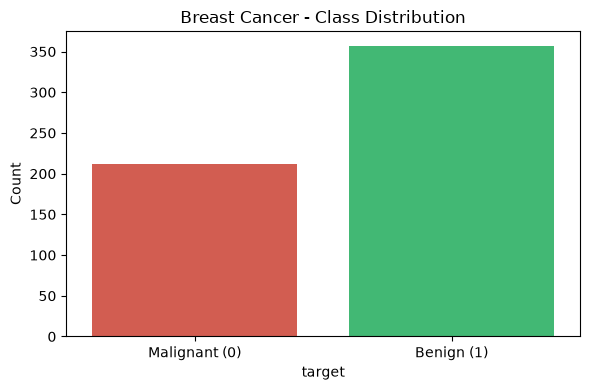

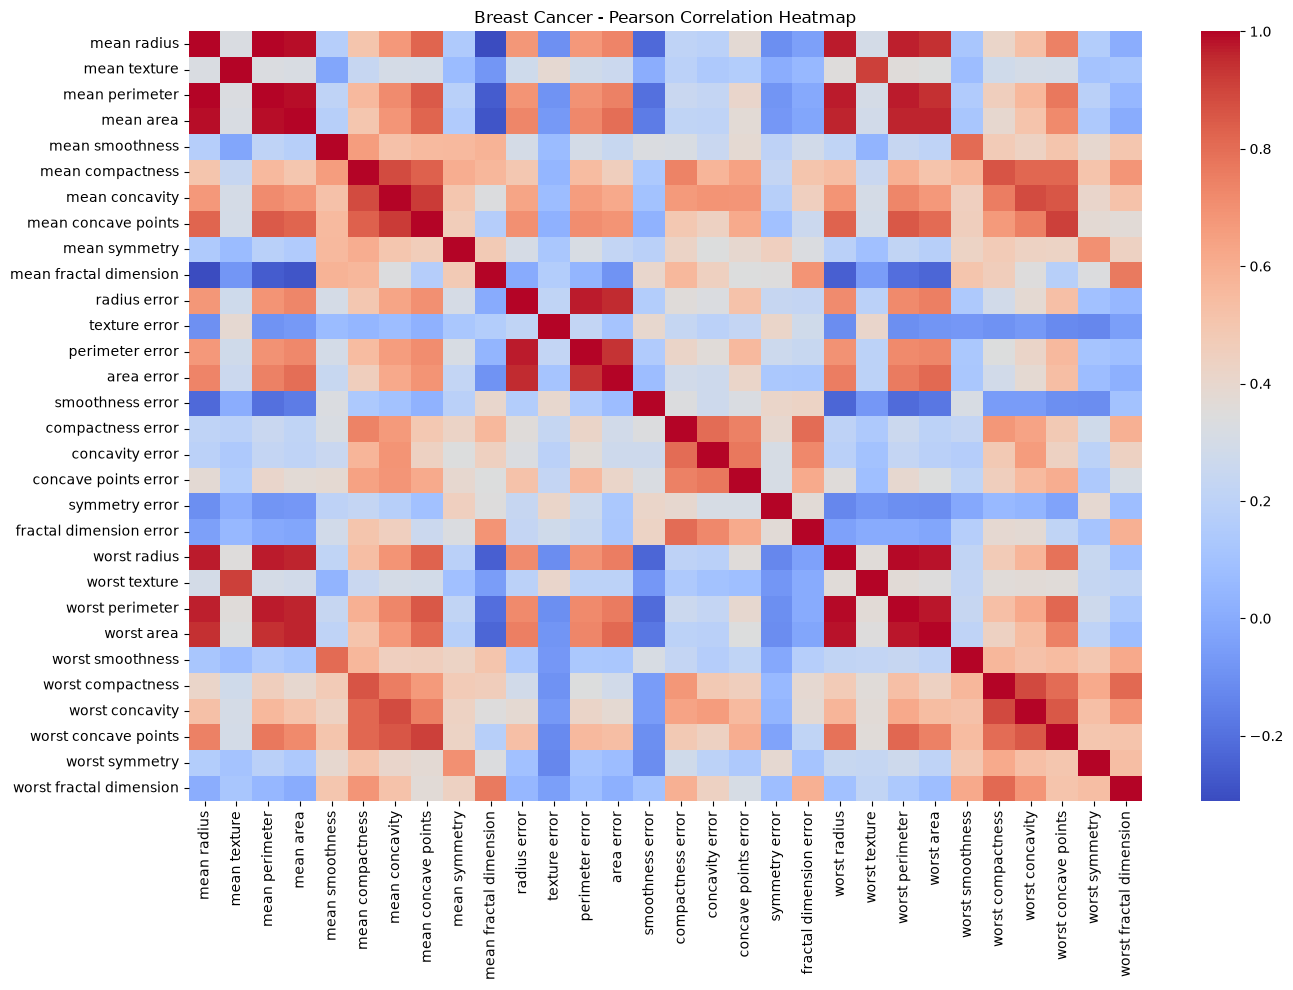


Top 3 Strongest Unique Feature Pairs (Absolute Correlation):
mean radius      mean perimeter    0.997855
worst perimeter  worst radius      0.993708
mean radius      mean area         0.987357
dtype: float64


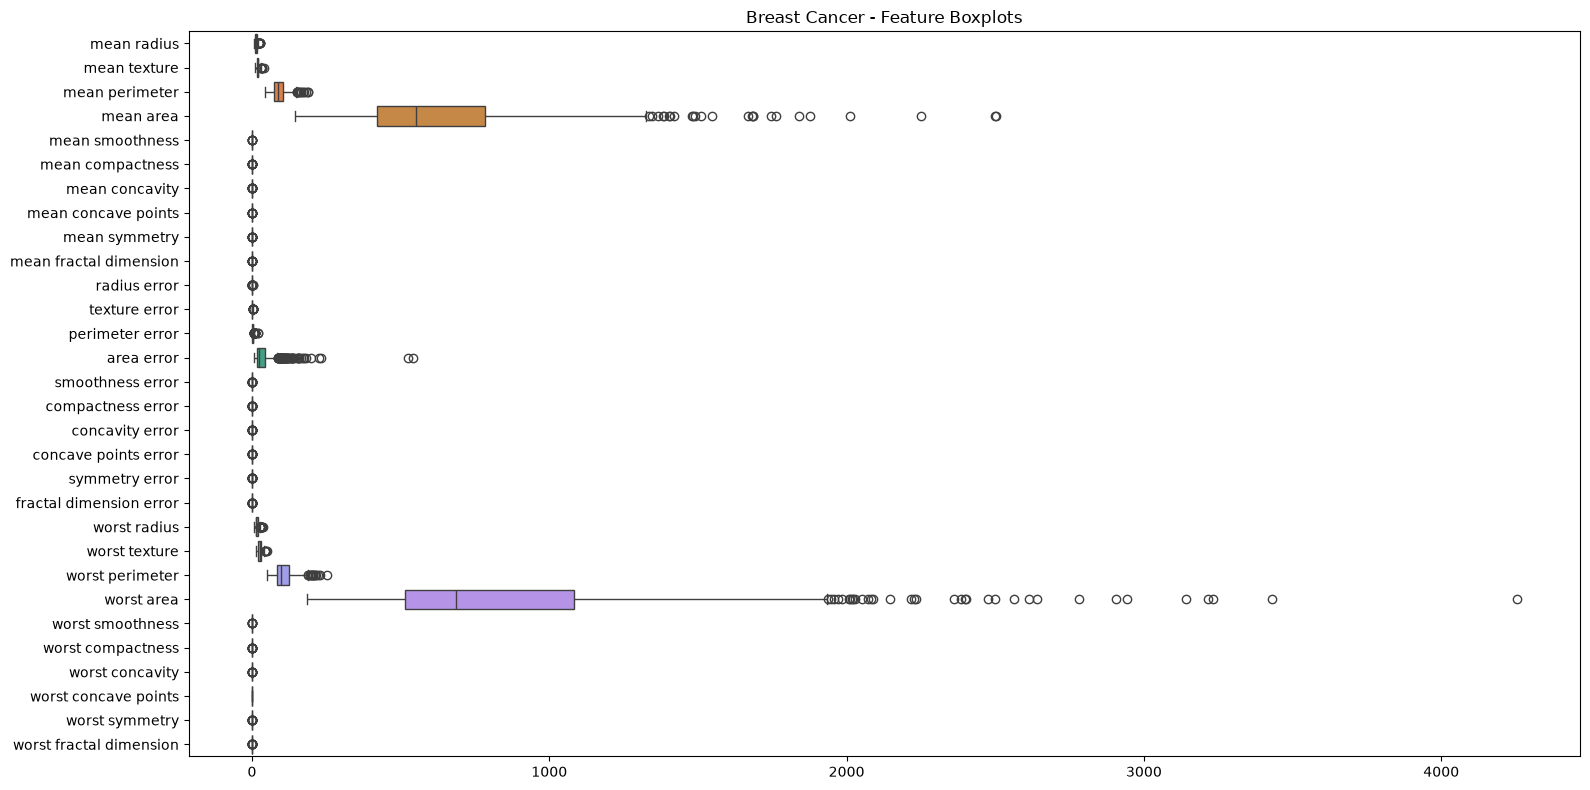

In [14]:
#  Exploratory Data Analysis (EDA)
#  Descriptive statistics

desc_stats = X.describe().T
desc_stats['median'] = X.median()
desc_stats['Q1'] = X.quantile(0.25)
desc_stats['Q3'] = X.quantile(0.75)


display(desc_stats[['mean', 'std', 'min', 'Q1', 'median', 'Q3', 'max']])

#  Class Distribution Plot
plt.figure(figsize=(6, 4))
sns.countplot(x=y, palette=['#e74c3c', '#2ecc71'])
plt.title('Breast Cancer - Class Distribution')
plt.xticks(ticks=[0, 1], labels=['Malignant (0)', 'Benign (1)'])
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('figures/cancer_class_distribution.png')
plt.show()

# Heatmap
plt.figure(figsize=(14, 10))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, fmt=".2f")
plt.title('Breast Cancer - Pearson Correlation Heatmap')
plt.tight_layout()
plt.savefig('figures/cancer_correlation_heatmap.png')
plt.show()

# 3 feature pairs by absolute correlation
corr_pairs = corr_matrix.abs().unstack()
corr_pairs = corr_pairs[corr_pairs < 1.0].sort_values(ascending=False).drop_duplicates()
print("\nTop 3 Strongest Unique Feature Pairs (Absolute Correlation):")
print(corr_pairs.head(3))

#  Boxplots
plt.figure(figsize=(16, 8))
sns.boxplot(data=X, orient='h')
plt.title('Breast Cancer - Feature Boxplots')
plt.tight_layout()
plt.savefig('figures/cancer_boxplots.png')
plt.show()

In [15]:

#  Splitting the Dataset
from sklearn.model_selection import train_test_split

SEEDS = [42, 52, 62]

# Fixed 20% Test split (Test set remains fixed across all experiments)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Store sub-datasets and summary rows for each seed
splits = {}
split_summary_rows = []

for seed in SEEDS:
    # Split the remaining 80% into 70% Train and 10% Validation (0.125 * 0.80 = 0.10)
    X_tr, X_v, y_tr, y_v = train_test_split(
        X_train_val, y_train_val, test_size=0.125, stratify=y_train_val, random_state=seed
    )
    
    splits[seed] = {
        'X_train': X_tr, 'X_val': X_v, 'X_test': X_test,
        'y_train': y_tr, 'y_val': y_v, 'y_test': y_test
    }
    
    # Store summary metrics for reporting
    for name, sub_x, sub_y in [('Train', X_tr, y_tr), ('Validation', X_v, y_v), ('Test', X_test, y_test)]:
        c_counts = sub_y.value_counts().to_dict()
        split_summary_rows.append({
            'Seed': seed, 'Subset': name,
            'Total Samples': len(sub_x),
            'Percentage (%)': round(len(sub_x) / len(X) * 100, 2),
            'Class 0 (Malignant)': c_counts.get(0, 0),
            'Class 1 (Benign)': c_counts.get(1, 0)
        })

split_summary_df = pd.DataFrame(split_summary_rows)
print("=== BREAST CANCER SPLIT SUMMARY TABLE (9 ROWS) ===")
print(split_summary_df.to_string(index=False))

print(f"\nFixed Test Indices Count: {len(X_test.index)}")

=== BREAST CANCER SPLIT SUMMARY TABLE (9 ROWS) ===
 Seed     Subset  Total Samples  Percentage (%)  Class 0 (Malignant)  Class 1 (Benign)
   42      Train            398           69.95                  149               249
   42 Validation             57           10.02                   21                36
   42       Test            114           20.04                   42                72
   52      Train            398           69.95                  149               249
   52 Validation             57           10.02                   21                36
   52       Test            114           20.04                   42                72
   62      Train            398           69.95                  149               249
   62 Validation             57           10.02                   21                36
   62       Test            114           20.04                   42                72

Fixed Test Indices Count: 114


In [16]:
# Model Training and Evaluation (Decision Tree, KNN, Naive Bayes)
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
    'NaiveBayes': GaussianNB()
}

results_rows = []

for seed, data_split in splits.items():
    X_tr = data_split['X_train']
    y_tr = data_split['y_train']
    X_va = data_split['X_val']
    y_va = data_split['y_val']
    
    # Standardize features (Fit on train, transform on validation and test)
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_va_scaled = scaler.transform(X_va)
    
    for model_name, model in models.items():
        # Train model
        model.fit(X_tr_scaled, y_tr)
        
        # Predictions
        preds = model.predict(X_va_scaled)
        probs = model.predict_proba(X_va_scaled)[:, 1] if hasattr(model, "predict_proba") else [0]*len(y_va)
        
        # Metrics
        acc = accuracy_score(y_va, preds)
        prec = precision_score(y_va, preds, zero_division=0)
        rec = recall_score(y_va, preds, zero_division=0)
        f1 = f1_score(y_va, preds, zero_division=0)
        roc = roc_auc_score(y_va, probs)
        
        results_rows.append({
            'Seed': seed,
            'Model': model_name,
            'Accuracy': round(acc, 4),
            'Precision': round(prec, 4),
            'Recall': round(rec, 4),
            'F1-Score': round(f1, 4),
            'ROC-AUC': round(roc, 4)
        })

results_df = pd.DataFrame(results_rows)
results_df.to_csv('csv_results/cancer_model_results.csv', index=False)

print("=== BREAST CANCER MODEL EVALUATION RESULTS ===")
print(results_df.to_string(index=False))

=== BREAST CANCER MODEL EVALUATION RESULTS ===
 Seed        Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
   42 DecisionTree    0.9298     0.9444  0.9444    0.9444   0.9246
   42          KNN    0.9474     0.9231  1.0000    0.9600   0.9669
   42   NaiveBayes    0.9298     0.9444  0.9444    0.9444   0.9775
   52 DecisionTree    0.8947     0.9412  0.8889    0.9143   0.8968
   52          KNN    0.9474     0.9231  1.0000    0.9600   0.9722
   52   NaiveBayes    0.9123     0.9189  0.9444    0.9315   0.9603
   62 DecisionTree    0.9123     0.9697  0.8889    0.9275   0.9206
   62          KNN    0.9825     0.9730  1.0000    0.9863   0.9993
   62   NaiveBayes    0.9474     1.0000  0.9167    0.9565   0.9894


In [17]:
 # PREPARING REPRESENTATIONS & MODEL TRAINING (66 RUNS)

import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

os.makedirs('csv_results', exist_ok=True)
classifier_runs = []

dt_depths = [2, 3, 5, 10, None]
knn_neighbors = [1, 3, 5, 7, 11]

for seed, data_split in splits.items():
    X_tr = data_split['X_train']
    y_tr = data_split['y_train']
    X_va = data_split['X_val']
    y_va = data_split['y_val']
    
    # Preprocessing (Fit on training data only)
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_va_scaled = scaler.transform(X_va)
    
    representations = {
        'unscaled': (X_tr, X_va),
        'scaled': (X_tr_scaled, X_va_scaled)
    }
    
    for rep_name, (X_t, X_v) in representations.items():
        
        # Decision Trees (5 Settings)
        for depth in dt_depths:
            depth_label = 'None' if depth is None else depth
            run_id = f"breast_cancer_dt_{rep_name}_d{depth_label}_s{seed}"
            model = DecisionTreeClassifier(max_depth=depth, random_state=seed)
            model.fit(X_t, y_tr)
            
            preds = model.predict(X_v)
            probs = model.predict_proba(X_v)
            # Binary ROC-AUC: Class 0 (malignant) treated as positive class
            malignant_probs = probs[:, 0]
            binary_val_target = (y_va == 0).astype(int)
            
            classifier_runs.append({
                'run_id': run_id, 'dataset': 'Breast Cancer', 'seed': seed,
                'algorithm': 'DecisionTree', 'representation': rep_name,
                'parameter': f"max_depth={depth_label}",
                'train_acc': round(accuracy_score(y_tr, model.predict(X_t)), 4),
                'train_f1': round(f1_score(y_tr, model.predict(X_t), average='macro', zero_division=0), 4),
                'val_acc': round(accuracy_score(y_va, preds), 4),
                'val_precision': round(precision_score(y_va, preds, average='macro', zero_division=0), 4),
                'val_recall': round(recall_score(y_va, preds, average='macro', zero_division=0), 4),
                'val_f1': round(f1_score(y_va, preds, average='macro', zero_division=0), 4),
                'val_roc_auc': round(roc_auc_score(binary_val_target, malignant_probs), 4)
            })
            
        # KNN (5 Settings)
        for k in knn_neighbors:
            run_id = f"breast_cancer_knn_{rep_name}_k{k}_s{seed}"
            model = KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')
            model.fit(X_t, y_tr)
            
            preds = model.predict(X_v)
            probs = model.predict_proba(X_v)
            malignant_probs = probs[:, 0]
            binary_val_target = (y_va == 0).astype(int)
            
            classifier_runs.append({
                'run_id': run_id, 'dataset': 'Breast Cancer', 'seed': seed,
                'algorithm': 'KNN', 'representation': rep_name,
                'parameter': f"n_neighbors={k}",
                'train_acc': round(accuracy_score(y_tr, model.predict(X_t)), 4),
                'train_f1': round(f1_score(y_tr, model.predict(X_t), average='macro', zero_division=0), 4),
                'val_acc': round(accuracy_score(y_va, preds), 4),
                'val_precision': round(precision_score(y_va, preds, average='macro', zero_division=0), 4),
                'val_recall': round(recall_score(y_va, preds, average='macro', zero_division=0), 4),
                'val_f1': round(f1_score(y_va, preds, average='macro', zero_division=0), 4),
                'val_roc_auc': round(roc_auc_score(binary_val_target, malignant_probs), 4)
            })
            
        #  Naive Bayes (1 Setting)
        run_id = f"breast_cancer_nb_{rep_name}_default_s{seed}"
        model = GaussianNB()
        model.fit(X_t, y_tr)
        
        preds = model.predict(X_v)
        probs = model.predict_proba(X_v)
        malignant_probs = probs[:, 0]
        binary_val_target = (y_va == 0).astype(int)
        
        classifier_runs.append({
            'run_id': run_id, 'dataset': 'Breast Cancer', 'seed': seed,
            'algorithm': 'GaussianNB', 'representation': rep_name,
            'parameter': 'default',
            'train_acc': round(accuracy_score(y_tr, model.predict(X_t)), 4),
            'train_f1': round(f1_score(y_tr, model.predict(X_t), average='macro', zero_division=0), 4),
            'val_acc': round(accuracy_score(y_va, preds), 4),
            'val_precision': round(precision_score(y_va, preds, average='macro', zero_division=0), 4),
            'val_recall': round(recall_score(y_va, preds, average='macro', zero_division=0), 4),
            'val_f1': round(f1_score(y_va, preds, average='macro', zero_division=0), 4),
            'val_roc_auc': round(roc_auc_score(binary_val_target, malignant_probs), 4)
        })

df_classifier_runs = pd.DataFrame(classifier_runs)
print(f"Total Classifier Runs Completed: {len(df_classifier_runs)}")
display(df_classifier_runs.head())

Total Classifier Runs Completed: 66


,run_id,dataset,seed,algorithm,representation,parameter,train_acc,train_f1,val_acc,val_precision,val_recall,val_f1,val_roc_auc
0,breast_cancer_dt_unscaled_d2_s42,Breast Cancer,42,DecisionTree,unscaled,max_depth=2,0.9548,0.9516,0.8947,0.8947,0.8770,0.8845,0.8757
1,breast_cancer_dt_unscaled_d3_s42,Breast Cancer,42,DecisionTree,unscaled,max_depth=3,0.9724,0.9700,0.8947,0.8947,0.8770,0.8845,0.9193
2,breast_cancer_dt_unscaled_d5_s42,Breast Cancer,42,DecisionTree,unscaled,max_depth=5,0.9975,0.9973,0.9123,0.9095,0.9008,0.9048,0.9213
3,breast_cancer_dt_unscaled_d10_s42,Breast Cancer,42,DecisionTree,unscaled,max_depth=10,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246
4,breast_cancer_dt_unscaled_dNone_s42,Breast Cancer,42,DecisionTree,unscaled,max_depth=None,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246


=== BREAST CANCER CLASSIFIER SUMMARY TABLE (22 CONFIGURATIONS) ===


,dataset,algorithm,representation,parameter,mean_train_acc,std_train_acc,mean_val_acc,std_val_acc,mean_val_precision,std_val_precision,mean_val_recall,std_val_recall,mean_val_f1,std_val_f1,mean_val_roc_auc,std_val_roc_auc
0,Breast Cancer,DecisionTree,scaled,max_depth=10,1.0000,0.0000,0.9240,0.0101,0.9159,0.0113,0.9266,0.0169,0.9194,0.0112,0.9266,0.0169
1,Breast Cancer,DecisionTree,scaled,max_depth=2,0.9556,0.0038,0.9181,0.0203,0.9131,0.0161,0.9120,0.0307,0.9117,0.0236,0.9220,0.0404
2,Breast Cancer,DecisionTree,scaled,max_depth=3,0.9757,0.0038,0.9240,0.0268,0.9199,0.0232,0.9167,0.0364,0.9177,0.0303,0.9414,0.0210
3,Breast Cancer,DecisionTree,scaled,max_depth=5,0.9950,0.0044,0.9240,0.0203,0.9167,0.0183,0.9233,0.0307,0.9188,0.0227,0.9301,0.0250
4,Breast Cancer,DecisionTree,scaled,max_depth=None,1.0000,0.0000,0.9240,0.0101,0.9159,0.0113,0.9266,0.0169,0.9194,0.0112,0.9266,0.0169
5,Breast Cancer,DecisionTree,unscaled,max_depth=10,1.0000,0.0000,0.9240,0.0101,0.9159,0.0113,0.9266,0.0169,0.9194,0.0112,0.9266,0.0169
6,Breast Cancer,DecisionTree,unscaled,max_depth=2,0.9556,0.0038,0.9181,0.0203,0.9131,0.0161,0.9120,0.0307,0.9117,0.0236,0.9220,0.0404
7,Breast Cancer,DecisionTree,unscaled,max_depth=3,0.9757,0.0038,0.9240,0.0268,0.9199,0.0232,0.9167,0.0364,0.9177,0.0303,0.9414,0.0210
8,Breast Cancer,DecisionTree,unscaled,max_depth=5,0.9950,0.0044,0.9240,0.0203,0.9167,0.0183,0.9233,0.0307,0.9188,0.0227,0.9301,0.0250
9,Breast Cancer,DecisionTree,unscaled,max_depth=None,1.0000,0.0000,0.9240,0.0101,0.9159,0.0113,0.9266,0.0169,0.9194,0.0112,0.9266,0.0169



SELECTED BEST CONFIGURATION FOR BREAST CANCER DATASET:
Algorithm: KNN
Representation: scaled
Parameter: n_neighbors=7
Mean Validation Macro-F1: 0.9677 ± 0.0297



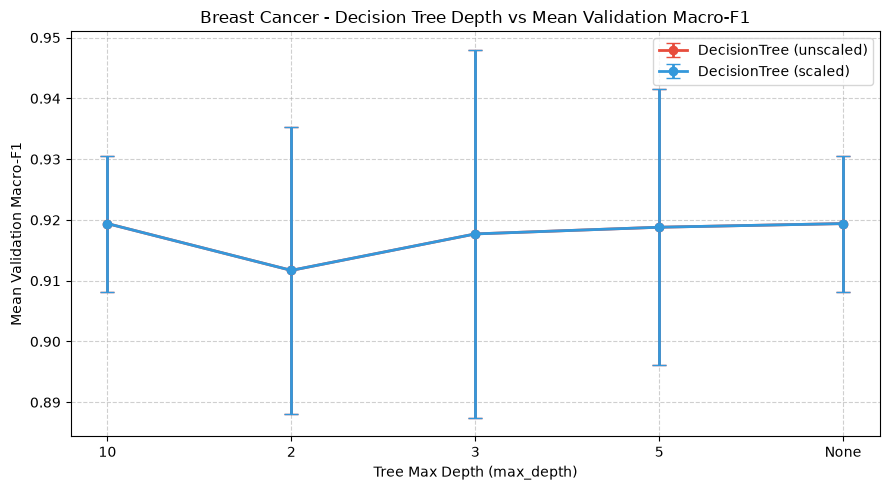

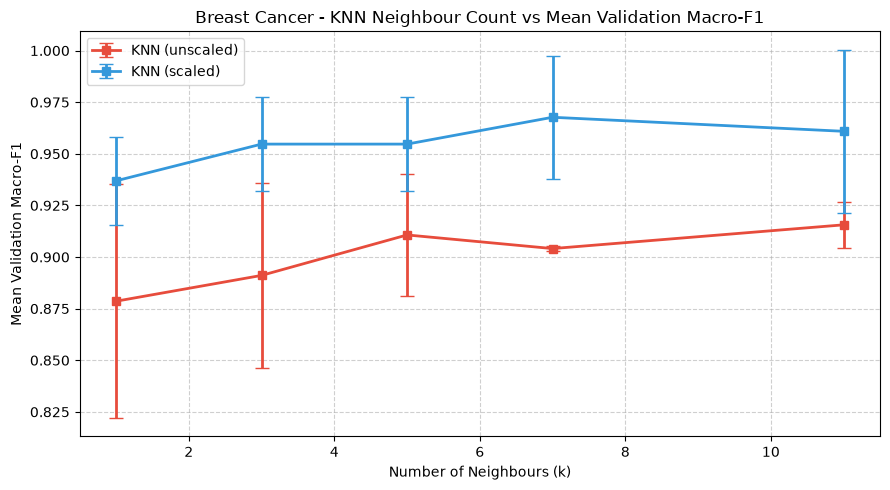

=== FINAL TEST EVALUATION RESULTS (SEED 42) ===
Test Accuracy: 0.9737 | Test Precision: 0.9800 | Test Recall: 0.9643 | Test F1: 0.9713 | Test ROC-AUC: 0.9888

=== CLASSIFICATION REPORT ===
               precision    recall  f1-score   support

malignant (0)       1.00      0.93      0.96        42
   benign (1)       0.96      1.00      0.98        72

     accuracy                           0.97       114
    macro avg       0.98      0.96      0.97       114
 weighted avg       0.97      0.97      0.97       114



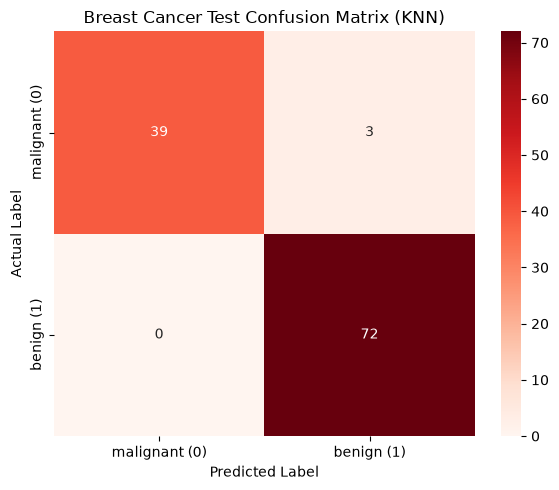

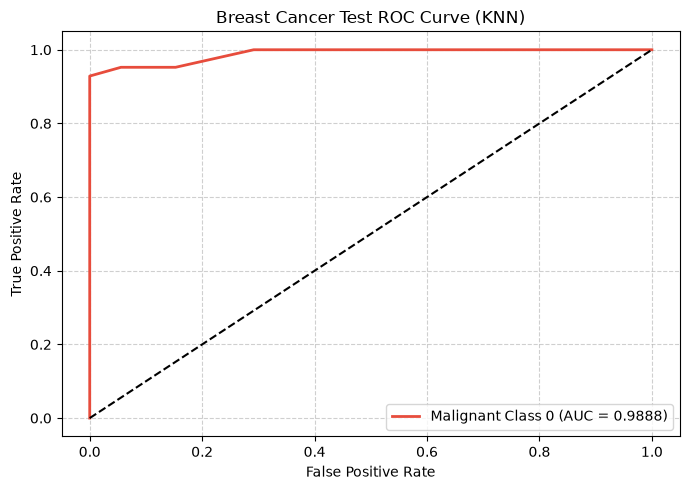

In [18]:

#SUMMARY TABLE, FIGURES & FINAL TEST EVALUATION (BREAST CANCER)

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report, confusion_matrix, 
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc
)
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

#  22 Configuration Summary Table
classifier_summary = df_classifier_runs.groupby(
    ['dataset', 'algorithm', 'representation', 'parameter']
).agg(
    mean_train_acc=('train_acc', 'mean'),
    std_train_acc=('train_acc', lambda x: x.std(ddof=1)),
    mean_val_acc=('val_acc', 'mean'),
    std_val_acc=('val_acc', lambda x: x.std(ddof=1)),
    mean_val_precision=('val_precision', 'mean'),
    std_val_precision=('val_precision', lambda x: x.std(ddof=1)),
    mean_val_recall=('val_recall', 'mean'),
    std_val_recall=('val_recall', lambda x: x.std(ddof=1)),
    mean_val_f1=('val_f1', 'mean'),
    std_val_f1=('val_f1', lambda x: x.std(ddof=1)),
    mean_val_roc_auc=('val_roc_auc', 'mean'),
    std_val_roc_auc=('val_roc_auc', lambda x: x.std(ddof=1))
).reset_index()

for col in classifier_summary.columns:
    if col not in ['dataset', 'algorithm', 'representation', 'parameter']:
        classifier_summary[col] = classifier_summary[col].round(4)

print("=== BREAST CANCER CLASSIFIER SUMMARY TABLE (22 CONFIGURATIONS) ===")
display(classifier_summary)

#  Select Best Configuration based on Validation Macro-F1
best_config = classifier_summary.sort_values(
    by=['mean_val_f1', 'mean_val_acc', 'std_val_f1'], 
    ascending=[False, False, True]
).iloc[0]

print("\n" + "="*50)
print(f"SELECTED BEST CONFIGURATION FOR BREAST CANCER DATASET:")
print(f"Algorithm: {best_config['algorithm']}")
print(f"Representation: {best_config['representation']}")
print(f"Parameter: {best_config['parameter']}")
print(f"Mean Validation Macro-F1: {best_config['mean_val_f1']:.4f} ± {best_config['std_val_f1']:.4f}")
print("="*50 + "\n")

#  Parameter Comparison Figures
os.makedirs('figures', exist_ok=True)

dt_data = classifier_summary[classifier_summary['algorithm'] == 'DecisionTree'].copy()
dt_data['depth_val'] = dt_data['parameter'].str.replace('max_depth=', '')

plt.figure(figsize=(9, 5))
for rep, color in [('unscaled', '#e74c3c'), ('scaled', '#3498db')]:
    sub = dt_data[dt_data['representation'] == rep]
    plt.errorbar(
        x=sub['depth_val'], y=sub['mean_val_f1'], yerr=sub['std_val_f1'], 
        label=f"DecisionTree ({rep})", capsize=5, marker='o', color=color, linewidth=2
    )

plt.title('Breast Cancer - Decision Tree Depth vs Mean Validation Macro-F1')
plt.xlabel('Tree Max Depth (max_depth)')
plt.ylabel('Mean Validation Macro-F1')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('figures/breast_cancer_dt_depth_comparison.png')
plt.show()

knn_data = classifier_summary[classifier_summary['algorithm'] == 'KNN'].copy()
knn_data['k_val'] = knn_data['parameter'].str.replace('n_neighbors=', '').astype(int)
knn_data = knn_data.sort_values(by='k_val')

plt.figure(figsize=(9, 5))
for rep, color in [('unscaled', '#e74c3c'), ('scaled', '#3498db')]:
    sub = knn_data[knn_data['representation'] == rep]
    plt.errorbar(
        x=sub['k_val'], y=sub['mean_val_f1'], yerr=sub['std_val_f1'], 
        label=f"KNN ({rep})", capsize=5, marker='s', color=color, linewidth=2
    )

plt.title('Breast Cancer - KNN Neighbour Count vs Mean Validation Macro-F1')
plt.xlabel('Number of Neighbours (k)')
plt.ylabel('Mean Validation Macro-F1')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('figures/breast_cancer_knn_k_comparison.png')
plt.show()

# 4. Final Evaluation on Seed 42 Test Set
X_tr_42 = splits[42]['X_train']
y_tr_42 = splits[42]['y_train']
X_te_fixed = splits[42]['X_test']
y_te_fixed = splits[42]['y_test']

scaler_42 = StandardScaler()
X_tr_42_scaled = scaler_42.fit_transform(X_tr_42)
X_te_fixed_scaled = scaler_42.transform(X_te_fixed)

if best_config['algorithm'] == 'KNN':
    k_val = int(best_config['parameter'].split('=')[1])
    final_model = KNeighborsClassifier(n_neighbors=k_val, weights='uniform', metric='euclidean')
elif best_config['algorithm'] == 'DecisionTree':
    depth_str = best_config['parameter'].split('=')[1]
    depth_val = None if depth_str == 'None' else int(depth_str)
    final_model = DecisionTreeClassifier(max_depth=depth_val, random_state=42)
else:
    final_model = GaussianNB()

if best_config['representation'] == 'scaled':
    X_train_final, X_test_final = X_tr_42_scaled, X_te_fixed_scaled
else:
    X_train_final, X_test_final = X_tr_42, X_te_fixed

final_model.fit(X_train_final, y_tr_42)
y_test_pred = final_model.predict(X_test_final)
y_test_proba = final_model.predict_proba(X_test_final)

y_test_proba_malignant = y_test_proba[:, 0]
y_test_binary_target = (y_te_fixed == 0).astype(int)

test_acc = accuracy_score(y_te_fixed, y_test_pred)
test_prec = precision_score(y_te_fixed, y_test_pred, average='macro', zero_division=0)
test_rec = recall_score(y_te_fixed, y_test_pred, average='macro', zero_division=0)
test_f1 = f1_score(y_te_fixed, y_test_pred, average='macro', zero_division=0)
test_roc_auc = roc_auc_score(y_test_binary_target, y_test_proba_malignant)

print("=== FINAL TEST EVALUATION RESULTS (SEED 42) ===")
print(f"Test Accuracy: {test_acc:.4f} | Test Precision: {test_prec:.4f} | Test Recall: {test_rec:.4f} | Test F1: {test_f1:.4f} | Test ROC-AUC: {test_roc_auc:.4f}\n")

print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_te_fixed, y_test_pred, target_names=['malignant (0)', 'benign (1)']))

# Confusion Matrix
cm = confusion_matrix(y_te_fixed, y_test_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=['malignant (0)', 'benign (1)'],
            yticklabels=['malignant (0)', 'benign (1)'])
plt.title(f'Breast Cancer Test Confusion Matrix ({best_config["algorithm"]})')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.savefig('figures/breast_cancer_test_confusion_matrix.png')
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test_binary_target, y_test_proba_malignant)
roc_auc_val = auc(fpr, tpr)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#e74c3c', lw=2, label=f'Malignant Class 0 (AUC = {roc_auc_val:.4f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'Breast Cancer Test ROC Curve ({best_config["algorithm"]})')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('figures/breast_cancer_test_roc_curve.png')
plt.show()

=== BREAST CANCER K-MEANS RUNS ===


,run_id,dataset,seed,representation,n_clusters,train_inertia,val_ari,val_silhouette
0,breast_cancer_kmeans_unscaled_k2_s42,Breast Cancer,42,unscaled,2,5.156538e+07,0.3995,0.6387
1,breast_cancer_kmeans_scaled_k2_s42,Breast Cancer,42,scaled,2,7.918810e+03,0.4516,0.2854
2,breast_cancer_kmeans_unscaled_k2_s52,Breast Cancer,52,unscaled,2,4.919078e+07,0.6122,0.6975
3,breast_cancer_kmeans_scaled_k2_s52,Breast Cancer,52,scaled,2,8.003001e+03,0.5586,0.3750
4,breast_cancer_kmeans_unscaled_k2_s62,Breast Cancer,62,unscaled,2,5.305649e+07,0.5013,0.6958
5,breast_cancer_kmeans_scaled_k2_s62,Breast Cancer,62,scaled,2,7.922515e+03,0.7336,0.2758



=== BREAST CANCER K-MEANS SUMMARY ===


,dataset,representation,mean_train_inertia,std_train_inertia,mean_val_ari,std_val_ari,mean_val_silhouette,std_val_silhouette
0,Breast Cancer,scaled,7.948109e+03,4.757423e+01,0.581267,0.142360,0.312067,0.054713
1,Breast Cancer,unscaled,5.127088e+07,1.949607e+06,0.504333,0.106382,0.677333,0.033468



BREAST CANCER K-MEANS TEST CONTINGENCY TABLES (SEED 42)

--- Representation: UNSCALED ---
Test ARI: 0.5585 | Test Silhouette: 0.7120


Cluster ID,0,1
True Class,,
0,14,28
1,72,0


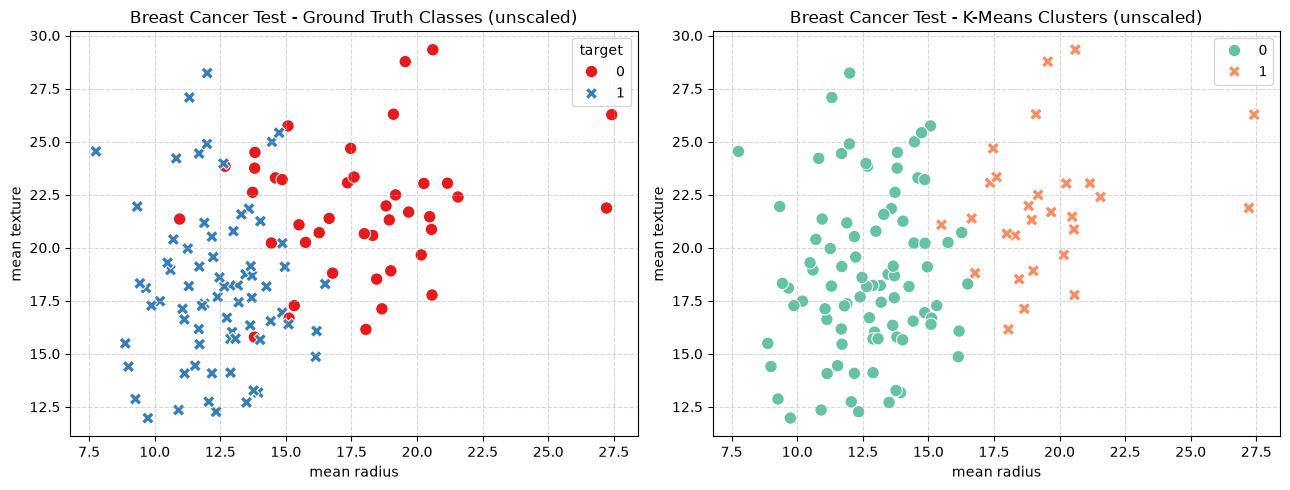


--- Representation: SCALED ---
Test ARI: 0.7354 | Test Silhouette: 0.3251


Cluster ID,0,1
True Class,,
0,5,37
1,69,3


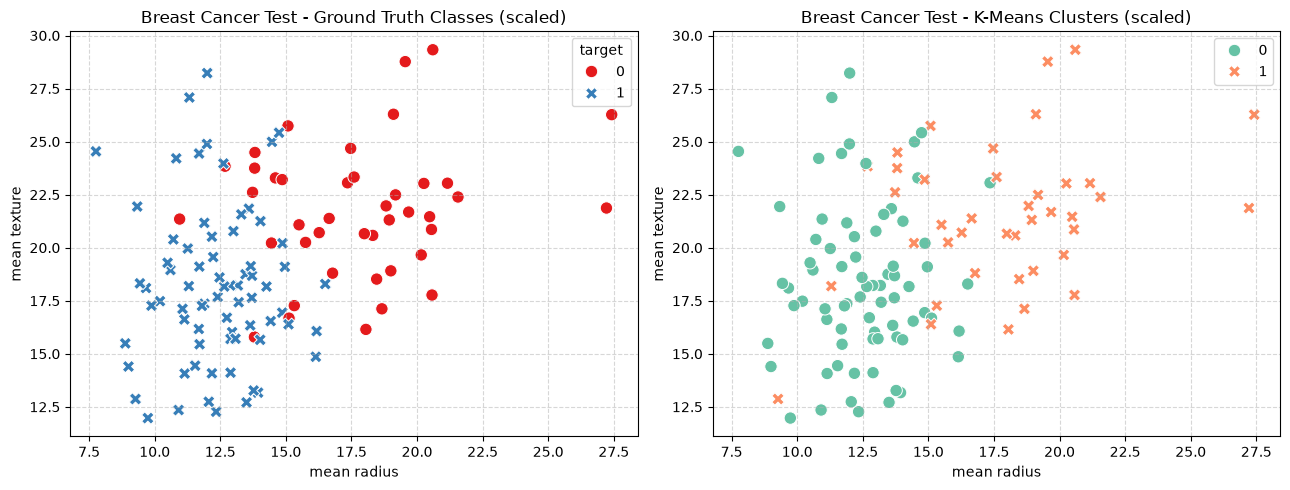

=== BREAST CANCER EXPORTS COMPLETED! ===


In [19]:

#  K-MEANS CLUSTERING & CSV EXPORTS (BREAST CANCER)

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

os.makedirs('figures', exist_ok=True)
os.makedirs('csv_results', exist_ok=True)
kmeans_runs = []

#  K-Means Fits (K=2, Unscaled & Scaled across 3 seeds)
for seed in SEEDS:
    X_tr = splits[seed]['X_train']
    y_tr = splits[seed]['y_train']
    X_va = splits[seed]['X_val']
    y_va = splits[seed]['y_val']
    
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_va_scaled = scaler.transform(X_va)
    
    reps = {
        'unscaled': (X_tr, X_va),
        'scaled': (X_tr_scaled, X_va_scaled)
    }
    
    for rep_name, (X_t, X_v) in reps.items():
        run_id = f"breast_cancer_kmeans_{rep_name}_k2_s{seed}"
        kmeans = KMeans(n_clusters=2, n_init=10, random_state=seed)
        kmeans.fit(X_t)  # Unsupervised: y_tr is NOT passed
        
        val_clusters = kmeans.predict(X_v)
        
        kmeans_runs.append({
            'run_id': run_id,
            'dataset': 'Breast Cancer',
            'seed': seed,
            'representation': rep_name,
            'n_clusters': 2,
            'train_inertia': round(kmeans.inertia_, 4),
            'val_ari': round(adjusted_rand_score(y_va, val_clusters), 4),
            'val_silhouette': round(silhouette_score(X_v, val_clusters), 4)
        })

df_kmeans_runs = pd.DataFrame(kmeans_runs)
print("=== BREAST CANCER K-MEANS RUNS ===")
display(df_kmeans_runs)

kmeans_summary = df_kmeans_runs.groupby(['dataset', 'representation']).agg(
    mean_train_inertia=('train_inertia', 'mean'),
    std_train_inertia=('train_inertia', lambda x: x.std(ddof=1)),
    mean_val_ari=('val_ari', 'mean'),
    std_val_ari=('val_ari', lambda x: x.std(ddof=1)),
    mean_val_silhouette=('val_silhouette', 'mean'),
    std_val_silhouette=('val_silhouette', lambda x: x.std(ddof=1))
).reset_index()

print("\n=== BREAST CANCER K-MEANS SUMMARY ===")
display(kmeans_summary)

# 2. Seed 42 Test Cluster Evaluation & Contingency Tables
X_tr_42 = splits[42]['X_train']
y_tr_42 = splits[42]['y_train']
X_te_42 = splits[42]['X_test']
y_te_42 = splits[42]['y_test']

scaler_42 = StandardScaler()
X_tr_42_scaled = scaler_42.fit_transform(X_tr_42)
X_te_42_scaled = scaler_42.transform(X_te_42)

test_reps = {
    'unscaled': (X_tr_42, X_te_42),
    'scaled': (X_tr_42_scaled, X_te_42_scaled)
}

kmeans_test_results = []
print("\n" + "="*50)
print("BREAST CANCER K-MEANS TEST CONTINGENCY TABLES (SEED 42)")
print("="*50)

for rep_name, (X_t, X_te) in test_reps.items():
    km = KMeans(n_clusters=2, n_init=10, random_state=42)
    km.fit(X_t)
    test_clusters = km.predict(X_te)
    
    contingency = pd.crosstab(y_te_42, test_clusters, rownames=['True Class'], colnames=['Cluster ID'])
    test_ari = adjusted_rand_score(y_te_42, test_clusters)
    test_sil = silhouette_score(X_te, test_clusters)
    
    kmeans_test_results.append({
        'dataset': 'Breast Cancer',
        'representation': rep_name,
        'evaluation_seed': 42,
        'n_clusters': 2,
        'test_ari': round(test_ari, 4),
        'test_silhouette': round(test_sil, 4)
    })
    
    print(f"\n--- Representation: {rep_name.upper()} ---")
    print(f"Test ARI: {test_ari:.4f} | Test Silhouette: {test_sil:.4f}")
    display(contingency)
    
    # 3. Paired Visualizations (mean radius vs mean texture)
    feat_x = 'mean radius'
    feat_y = 'mean texture'
    
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    
    sns.scatterplot(
        data=splits[42]['X_test'], x=feat_x, y=feat_y, hue=y_te_42,
        palette='Set1', style=y_te_42, s=80, ax=axes[0]
    )
    axes[0].set_title(f'Breast Cancer Test - Ground Truth Classes ({rep_name})')
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    sns.scatterplot(
        data=splits[42]['X_test'], x=feat_x, y=feat_y, hue=test_clusters,
        palette='Set2', style=test_clusters, s=80, ax=axes[1]
    )
    axes[1].set_title(f'Breast Cancer Test - K-Means Clusters ({rep_name})')
    axes[1].grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.savefig(f'figures/breast_cancer_kmeans_paired_{rep_name}.png')
    plt.show()

# 4. Exporting Individual Breast Cancer CSV Files
df_classifier_runs.to_csv('csv_results/breast_cancer_classifier_runs.csv', index=False)
classifier_summary.to_csv('csv_results/breast_cancer_classifier_summary.csv', index=False)

df_classifier_test = pd.DataFrame([{
    'dataset': 'Breast Cancer',
    'selected_configuration': f"{best_config['algorithm']}_{best_config['representation']}_{best_config['parameter']}",
    'evaluation_seed': 42,
    'mean_val_f1': best_config['mean_val_f1'],
    'std_val_f1': best_config['std_val_f1'],
    'test_acc': round(test_acc, 4),
    'test_precision': round(test_prec, 4),
    'test_recall': round(test_rec, 4),
    'test_f1': round(test_f1, 4),
    'test_roc_auc': round(test_roc_auc, 4)
}])
df_classifier_test.to_csv('csv_results/breast_cancer_classifier_test.csv', index=False)
df_kmeans_runs.to_csv('csv_results/breast_cancer_kmeans_runs.csv', index=False)
kmeans_summary.to_csv('csv_results/breast_cancer_kmeans_summary.csv', index=False)
pd.DataFrame(kmeans_test_results).to_csv('csv_results/breast_cancer_kmeans_test.csv', index=False)

print("=== BREAST CANCER EXPORTS COMPLETED! ===")